<a href="https://colab.research.google.com/github/MehboobAli-Portfolio/AI_Dairy_Lens/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [195]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
import os
import kagglehub
import shutil

In [196]:
path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset")
os.makedirs("dataset", exist_ok=True)
source = os.path.join(path,"Telco_customer_churn.xlsx")
destination = "dataset/Telco_customer_churn.xlsx"
shutil.copy2(source, destination)
print("Data save at",destination)

Using Colab cache for faster access to the 'telco-customer-churn-ibm-dataset' dataset.
Data save at dataset/Telco_customer_churn.xlsx


In [197]:
df = pd.read_excel(destination)
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [198]:
print(df.shape)
df.head()

(7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [199]:
df.info()
df.isna().sum().sort_values(ascending=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

,0
Churn Reason,5174
CustomerID,0
Count,0
State,0
Country,0
Zip Code,0
Lat Long,0
Latitude,0
City,0
Gender,0


In [200]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

correlation_matrix["Churn Value"].sort_values(ascending=False)


,Churn Value
Churn Value,1.000000
Churn Score,0.664897
Monthly Charges,0.193356
Longitude,0.004594
Zip Code,0.003346
Latitude,-0.003384
CLTV,-0.127463
Tenure Months,-0.352229
Count,NaN


In [201]:
print(df[["Churn Score", "CLTV", "Churn Value"]].describe())

print("\nAverage values by churn outcome:")
print(
    df.groupby("Churn Value")[["Churn Score", "CLTV"]].mean()
)

       Churn Score         CLTV  Churn Value
count  7043.000000  7043.000000  7043.000000
mean     58.699418  4400.295755     0.265370
std      21.525131  1183.057152     0.441561
min       5.000000  2003.000000     0.000000
25%      40.000000  3469.000000     0.000000
50%      61.000000  4527.000000     0.000000
75%      75.000000  5380.500000     1.000000
max     100.000000  6500.000000     1.000000

Average values by churn outcome:
             Churn Score         CLTV
Churn Value                          
0              50.098183  4490.921337
1              82.510433  4149.414660


In [202]:

drop_columns = [
    "CustomerID",     # Customer identifier
    "Count",          # Constant column
    "Country",        # Constant column
    "State",          # Constant column
    "City",           # Excluded from our first model
    "Zip Code",       # Location feature; excluded initially
    "Lat Long",       # Location feature; excluded initially
    "Latitude",       # Location feature; excluded initially
    "Longitude",      # Location feature; excluded initially
    "Churn Label",    # Duplicates the target
    "Churn Score",    # Excluded due to possible leakage
    "Churn Reason"    # Information recorded after churn
]

X = df.drop(columns=drop_columns)
y = df["Churn Value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nRemaining features:")
print(X.columns.tolist())


Features shape: (7043, 21)
Target shape: (7043,)

Remaining features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value', 'CLTV']


In [203]:

X = df.drop(columns=drop_columns + ["Churn Value"])
y = df["Churn Value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (7043, 20)
Target shape: (7043,)


In [204]:
X.dtypes
X.info()
X.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             7043 non-null   object 
 1   Senior Citizen     7043 non-null   object 
 2   Partner            7043 non-null   object 
 3   Dependents         7043 non-null   object 
 4   Tenure Months      7043 non-null   int64  
 5   Phone Service      7043 non-null   object 
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Streaming TV       7043 non-null   object 
 13  Streaming Movies   7043 non-null   object 
 14  Contract           7043 non-null   object 
 15  Paperless Billing  7043 non-null   object 
 16  Payment Method     7043 

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,CLTV
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,3239
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,2701
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,5372
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,5003
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,5340


In [205]:
X["Total Charges"] = pd.to_numeric(
    X["Total Charges"],
    errors="coerce"
).fillna(0)
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             7043 non-null   object 
 1   Senior Citizen     7043 non-null   object 
 2   Partner            7043 non-null   object 
 3   Dependents         7043 non-null   object 
 4   Tenure Months      7043 non-null   int64  
 5   Phone Service      7043 non-null   object 
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Streaming TV       7043 non-null   object 
 13  Streaming Movies   7043 non-null   object 
 14  Contract           7043 non-null   object 
 15  Paperless Billing  7043 non-null   object 
 16  Payment Method     7043 

In [206]:
categorical_columns = X.select_dtypes(include=["object"]).columns
numerical_columns = X.select_dtypes(include=["number"]).columns

print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))

Categorical columns: 16
Numerical columns: 4


In [207]:
X_categorical = pd.get_dummies(
    X[categorical_columns],
    dtype="float32"
)

print("Original categorical shape:", X[categorical_columns].shape)
print("Encoded categorical shape:", X_categorical.shape)

X_categorical.head()

Original categorical shape: (7043, 16)
Encoded categorical shape: (7043, 43)


,Gender_Female,Gender_Male,Senior Citizen_No,Senior Citizen_Yes,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,Phone Service_No,Phone Service_Yes,Multiple Lines_No,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_DSL,Internet Service_Fiber optic,Internet Service_No,Online Security_No,Online Security_No internet service,Online Security_Yes,Online Backup_No,Online Backup_No internet service,Online Backup_Yes,Device Protection_No,Device Protection_No internet service,Device Protection_Yes,Tech Support_No,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank transfer (automatic),Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [208]:
# Calculate the mean and standard deviation of each numerical column
mean = X_numerical.mean(axis=0)
std = X_numerical.std(axis=0)

# Avoid division by zero if any column has no variation
std = std.replace(0, 1)

# Standardize the numerical data
X_numerical = (X_numerical - mean) / std

# Display the standardized values
X_numerical.head()

,Tenure Months,Monthly Charges,Total Charges
0,-1.236636,-0.362635,-0.957998
1,-1.236636,0.197351,-0.938808
2,-0.992332,1.159463,-0.643744
3,-0.177982,1.330616,0.338061
4,0.677085,1.294059,1.216063


In [209]:
X_processed = pd.concat(
    [X_categorical, X_numerical],
    axis=1
)

print("Processed data shape:", X_processed.shape)

X_processed.head()

Processed data shape: (7043, 46)


,Gender_Female,Gender_Male,Senior Citizen_No,Senior Citizen_Yes,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,Phone Service_No,Phone Service_Yes,Multiple Lines_No,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_DSL,Internet Service_Fiber optic,Internet Service_No,Online Security_No,Online Security_No internet service,Online Security_Yes,Online Backup_No,Online Backup_No internet service,Online Backup_Yes,Device Protection_No,Device Protection_No internet service,Device Protection_Yes,Tech Support_No,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank transfer (automatic),Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check,Tenure Months,Monthly Charges,Total Charges
0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-1.236636,-0.362635,-0.957998
1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-1.236636,0.197351,-0.938808
2,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-0.992332,1.159463,-0.643744
3,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-0.177982,1.330616,0.338061
4,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.677085,1.294059,1.216063


In [221]:
def model_creation():
  model= keras.Sequential(
    [
      layers.Dense(64, activation="relu"),
      layers.Dense(32, activation="relu"),
      layers.Dense(32, activation="relu"),
      layers.Dense(1, activation="sigmoid"),
    ]
  )
  model.compile(
      optimizer="adam",
      loss="binary_crossentropy",
      metrics=["accuracy"]
  )
  return model


In [222]:
model = model_creation()
history = model.fit(
    X_train_array,
    y_train,
    epochs=20,
    batch_size=512,
    validation_split=0.2
)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 161ms/step - accuracy: 0.6870 - loss: 0.6208 - val_accuracy: 0.7343 - val_loss: 0.5595
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7408 - loss: 0.5208 - val_accuracy: 0.7475 - val_loss: 0.5040
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7738 - loss: 0.4685 - val_accuracy: 0.7789 - val_loss: 0.4744
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7989 - loss: 0.4402 - val_accuracy: 0.7718 - val_loss: 0.4620
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8052 - loss: 0.4248 - val_accuracy: 0.7799 - val_loss: 0.4591
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8106 - loss: 0.4146 - val_accuracy: 0.7809 - val_loss: 0.4546
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8131 - loss: 0.4071 - val_accuracy: 0.7850 - val_loss: 0.4466
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8164 - loss: 0.4023 - val_accuracy: 0.7819 - val_loss: 0.4430

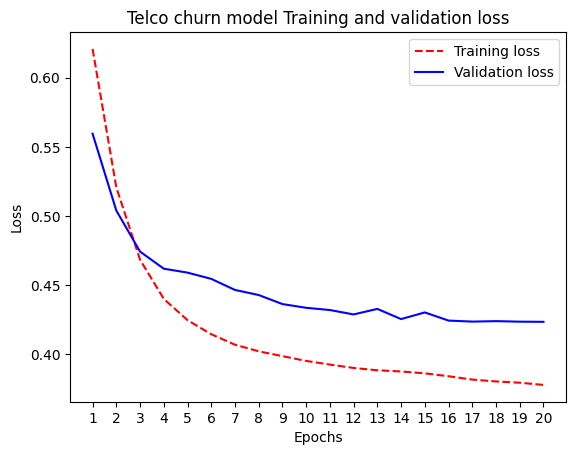

In [223]:
history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Telco churn model Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()


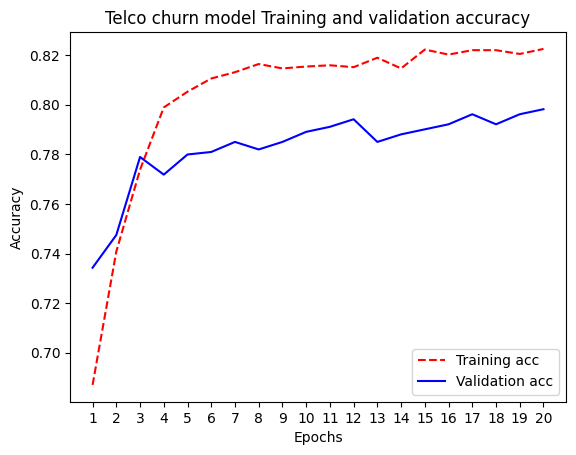

In [224]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Telco churn model Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [225]:
print("Training loss:", history.history["loss"][-1])
print("Training accuracy:", history.history["accuracy"][-1])

print("Validation loss:", history.history["val_loss"][-1])
print("Validation accuracy:", history.history["val_accuracy"][-1])

Training loss: 0.37800267338752747
Training accuracy: 0.8224701881408691
Validation loss: 0.4235963225364685
Validation accuracy: 0.7981744408607483


In [226]:
print(y.value_counts())
print()
print(y.value_counts(normalize=True) * 100)

Churn Value
0    5174
1    1869
Name: count, dtype: int64

Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [228]:

import numpy as np

# Predict churn probabilities for validation customers
predictions = model.predict(X_val_array).flatten()

# Convert probabilities into 0 or 1
predicted_classes = (predictions >= 0.5).astype(int)
actual_classes = y_val.astype(int)

# Count correct and incorrect churn predictions
true_positives = np.sum(
    (actual_classes == 1) & (predicted_classes == 1)
)

false_positives = np.sum(
    (actual_classes == 0) & (predicted_classes == 1)
)

false_negatives = np.sum(
    (actual_classes == 1) & (predicted_classes == 0)
)

# Calculate precision and recall
precision = true_positives / (true_positives + false_positives + 1e-7)
recall = true_positives / (true_positives + false_negatives + 1e-7)

print("Validation Precision:", round(precision * 100, 2), "%")
print("Validation Recall:", round(recall * 100, 2), "%")


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Validation Precision: 63.98 %
Validation Recall: 59.64 %


In [229]:

import numpy as np

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

print("Threshold | Precision | Recall | F1-score")
print("-" * 46)

for threshold in thresholds:
    # Convert probabilities into predicted classes
    predicted = (predictions >= threshold).astype(int)

    # Count prediction outcomes
    tp = np.sum((actual_classes == 1) & (predicted == 1))
    fp = np.sum((actual_classes == 0) & (predicted == 1))
    fn = np.sum((actual_classes == 1) & (predicted == 0))

    # Calculate precision and recall
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    # Calculate F1-score
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"{threshold:^9.1f} | "
        f"{precision:^9.3f} | "
        f"{recall:^6.3f} | "
        f"{f1:^8.3f}"
    )


Threshold | Precision | Recall | F1-score
----------------------------------------------
   0.3    |   0.527   | 0.754  |  0.621  
   0.4    |   0.580   | 0.675  |  0.624  
   0.5    |   0.640   | 0.596  |  0.617  
   0.6    |   0.738   | 0.454  |  0.562  
   0.7    |   0.743   | 0.279  |  0.405  
